# E01 — base layer (L1): relief, water, period borders
Task `tasks/T-006-e01-base-layers.md` (brief B-017). GIS processing only, no ML/LLM. Reads `data/raw/gis/` and `data/processed/`; writes only to `web/data/`.

**Sources** (`research/R6-layer-sources.md`, `docs/DATA.md`)
- Relief: NOAA NCEI ETOPO 2022, 30 arc-second, ice surface (NOAA NCEI 2022). ERDDAP subset lat 24–50, lon 260–296 (= −100…−64), 4321 × 3121 cells, NetCDF-3, metres above EGM2008. Modern surface; fine for a hillshade.
- Water: Natural Earth 10m physical v5.0.0 (Kelso and Patterson, n.d.), public domain: `rivers_lake_centerlines` + `rivers_north_america` (supplement, scalerank 10–12), `lakes` + `lakes_north_america` (supplement), `coastline`. Modern lines.
- Borders: Newberry Library, *Atlas of Historical County Boundaries* (AHCB), `US_HistStateTerr_Gen001` (220 versions, from 1783-09-03) and `US_HistCounties_Gen001` (17,727 versions). One row = one shape version with `START_DATE`–`END_DATE`.
- Extent: `data/processed/places.parquet` centroids of the places that appear in `residences.parquet` (A08).

**Grain of the outputs**
- `relief.png`: one hillshade cell per ETOPO cell (≈0.0083°), lon/lat grid; land only (ocean transparent). `relief_bounds.json` gives the corners for a deck.gl `BitmapLayer`.
- `relief_terrarium.png`: elevation, Terrarium RGB encoding, downsampled, for an optional `TerrainLayer` (named in task step 2, not in the Files list).
- `water.topojson`: objects `rivers`, `lakes`, `coast`; one feature per Natural Earth feature, clipped and simplified.
- `borders.topojson`: objects `states`, `counties`; one feature per Newberry shape version that exists in at least one snapshot. `years` lists the snapshots it belongs to, so a version unchanged 1800–1840 is stored once.

**Caveats up front**
- Relief, rivers, lakes and coast are modern. Modern reservoirs are dropped (`featurecla = Reservoir`); modern canals in the NA river file are dropped too (historic canals come from Atack in D01).
- Snapshot date = 31 December of each year. Newberry `Gen001` is the generalised edition (not for large scales).
- Polygons are clipped to the extent, so the extent edge shows up as a straight edge on lakes and borders.
- Simplification is per feature (no shared topology), so neighbouring county lines can differ by up to the tolerance (~500 m).

In [1]:
import sys, json, struct
from pathlib import Path
PIPELINE_DIR = Path.cwd().parent
if str(PIPELINE_DIR) not in sys.path: sys.path.insert(0, str(PIPELINE_DIR))
import config
import duckdb, numpy as np, pandas as pd, geopandas as gpd, shapely
from shapely.geometry import box
from PIL import Image
import matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_rows', 120)

GIS = config.RAW_DIR / 'gis'
WEB = config.PROJECT_DIR / 'web' / 'data'
WEB.mkdir(parents=True, exist_ok=True)
SNAPSHOTS = [1784, 1790, 1800, 1810, 1820, 1830, 1840]
MARGIN = 1.0           # degrees around the places
SIMPLIFY = 0.005       # degrees (~500 m) for water and borders
con = duckdb.connect()
con.sql(f"create view places as select * from read_parquet('{config.PROCESSED_DIR/'places.parquet'}')")
con.sql(f"create view residences as select * from read_parquet('{config.PROCESSED_DIR/'residences.parquet'}')")
def q(sql): return con.sql(sql).df()

In [2]:
# Helpers: a minimal NetCDF-3 reader (no netCDF library in the venv) and a TopoJSON writer/reader.
NC_T = {1: ('i1', 1), 2: ('S1', 1), 3: ('>i2', 2), 4: ('>i4', 4), 5: ('>f4', 4), 6: ('>f8', 8)}
def read_nc3(path):
    """Header of a NetCDF-3 classic / 64-bit-offset file (fixed-size variables only)."""
    buf = open(path, 'rb').read(1 << 20)
    assert buf[:3] == b'CDF', 'not NetCDF-3'
    off64, pos = buf[3] == 2, 8
    def u32():
        nonlocal pos; v = struct.unpack('>I', buf[pos:pos+4])[0]; pos += 4; return v
    def name():
        nonlocal pos; n = u32(); s = buf[pos:pos+n].decode(); pos += (n + 3) // 4 * 4; return s
    def attrs():
        nonlocal pos; u32(); out = {}
        for _ in range(u32()):
            k = name(); t = u32(); m = u32(); dt, sz = NC_T[t]
            raw = buf[pos:pos + m*sz]; pos += (m*sz + 3) // 4 * 4
            v = raw.decode(errors='replace') if t == 2 else np.frombuffer(raw, dt)
            out[k] = v if t == 2 or m > 1 else v[0]
        return out
    u32(); dims = [(name(), u32()) for _ in range(u32())]
    gatts = attrs(); u32(); vars_ = {}
    for _ in range(u32()):
        k = name(); ids = [u32() for _ in range(u32())]; va = attrs(); t = u32(); u32()
        if off64: begin = struct.unpack('>Q', buf[pos:pos+8])[0]; pos += 8
        else: begin = u32()
        vars_[k] = dict(dims=[dims[i][0] for i in ids], shape=tuple(dims[i][1] for i in ids),
                        dtype=NC_T[t][0], begin=begin, attrs=va)
    return gatts, vars_
def nc_var(path, v): return np.memmap(path, dtype=v['dtype'], mode='r', offset=v['begin'], shape=v['shape'])

def to_topojson(layers, q=100_000):
    """{object name: GeoDataFrame (EPSG:4326)} -> quantized TopoJSON dict. One arc per ring/line, no shared arcs."""
    b = np.array([g.total_bounds for g in layers.values() if len(g)])
    x0, y0, x1, y1 = b[:, 0].min(), b[:, 1].min(), b[:, 2].max(), b[:, 3].max()
    kx, ky = (x1 - x0) / (q - 1), (y1 - y0) / (q - 1)
    arcs = []
    def arc(coords, ring=False):
        xy = np.round((np.asarray(coords)[:, :2] - [x0, y0]) / [kx, ky]).astype(np.int64)
        xy = xy[np.r_[True, (np.diff(xy, axis=0) != 0).any(1)]]
        if len(xy) < (4 if ring else 2): return None
        arcs.append(np.vstack([xy[:1], np.diff(xy, axis=0)]).tolist()); return len(arcs) - 1
    def poly(p):
        rings = [arc(p.exterior.coords, True)] + [arc(r.coords, True) for r in p.interiors]
        return None if rings[0] is None else [r for r in rings if r is not None]
    def geom(g):
        t = g.geom_type
        if t == 'LineString':
            a = arc(g.coords); return a is not None and {'type': 'LineString', 'arcs': [a]}
        if t == 'MultiLineString':
            a = [[x] for x in (arc(l.coords) for l in g.geoms) if x is not None]
            return bool(a) and {'type': 'MultiLineString', 'arcs': a}
        if t == 'Polygon':
            p = poly(g); return p is not None and {'type': 'Polygon', 'arcs': p}
        if t == 'MultiPolygon':
            ps = [p for p in (poly(x) for x in g.geoms) if p is not None]
            return bool(ps) and {'type': 'MultiPolygon', 'arcs': ps}
        raise ValueError(t)
    objects = {}
    for name, gdf in layers.items():
        geoms = []
        for rec, g in zip(gdf.drop(columns='geometry').to_dict('records'), gdf.geometry):
            o = geom(g)
            if not o: continue
            o['properties'] = {k: v for k, v in rec.items() if v is not None and v == v}
            geoms.append(o)
        objects[name] = {'type': 'GeometryCollection', 'geometries': geoms}
    return {'type': 'Topology', 'bbox': [x0, y0, x1, y1],
            'transform': {'scale': [kx, ky], 'translate': [x0, y0]}, 'objects': objects, 'arcs': arcs}

def write_topojson(topo, path):
    path.write_text(json.dumps(topo, separators=(',', ':'), default=lambda v: v.item() if hasattr(v, 'item') else str(v)))
    return path.stat().st_size / 1e6

def read_topojson(path):
    """Decode a TopoJSON written above back to {object: GeoDataFrame} (used for the checks)."""
    t = json.loads(Path(path).read_text()); s, tr = t['transform']['scale'], t['transform']['translate']
    arcs = [np.cumsum(np.array(a), axis=0) * s + tr for a in t['arcs']]
    def line(i): return arcs[i] if i >= 0 else arcs[~i][::-1]
    def build(o):
        a = o['arcs']
        if o['type'] == 'LineString': return shapely.LineString(line(a[0]))
        if o['type'] == 'MultiLineString': return shapely.MultiLineString([line(x[0]) for x in a])
        if o['type'] == 'Polygon': return shapely.Polygon(line(a[0]), [line(r) for r in a[1:]])
        return shapely.MultiPolygon([shapely.Polygon(line(p[0]), [line(r) for r in p[1:]]) for p in a])
    return {k: gpd.GeoDataFrame([g['properties'] for g in v['geometries']],
                                geometry=[build(g) for g in v['geometries']], crs='EPSG:4326')
            for k, v in t['objects'].items()}, t

## 1. Extent
Bounding box of the `places` centroids that appear in `residences` (state rows use the state centroid), plus a 1° margin.

In [3]:
ext = q("""select count(distinct place_id) places, min(lon) lon_min, max(lon) lon_max, min(lat) lat_min, max(lat) lat_max
           from places where place_id in (select place_id from residences)""")
display(ext)
gatts, nv = read_nc3(next((GIS / 'etopo2022-30s').glob('*.nc')))
ETOPO_PATH = next((GIS / 'etopo2022-30s').glob('*.nc'))
h = float(gatts['geospatial_lat_resolution']) / 2      # geospatial_* are cell centres; the box is cell edges
etopo_box = (float(gatts['geospatial_lon_min']) - 360 - h, float(gatts['geospatial_lat_min']) - h,
             float(gatts['geospatial_lon_max']) - 360 + h, float(gatts['geospatial_lat_max']) + h)
want = (ext.lon_min[0] - MARGIN, ext.lat_min[0] - MARGIN, ext.lon_max[0] + MARGIN, ext.lat_max[0] + MARGIN)
print('places + margin :', np.round(want, 3))
print('ETOPO subset    :', np.round(etopo_box, 3))
outside = q(f"""select p.place_id, p.state, p.lon, p.lat, count(*) rows, count(distinct r.NAID) files
               from residences r join places p using(place_id)
               where p.lon < {etopo_box[0]} or p.lon > {etopo_box[2]} or p.lat < {etopo_box[1]} or p.lat > {etopo_box[3]}
               group by all order by p.lon""")
print('places outside the ETOPO subset:'); display(outside)

,places,lon_min,lon_max,lat_min,lat_max
0,1202,-123.5791,-67.6128,25.9114,46.4394


places + margin : [-124.579   24.911  -66.613   47.439]
ETOPO subset    : [-100.      24.     -63.992   50.008]
places outside the ETOPO subset:


,place_id,state,lon,lat,rows,files
0,ors_clatsop,Oregon Territory,-123.5791,45.8378,1,1
1,cas_butte,California,-121.0139,40.0026,2,2
2,cas_calaveras,California,-119.3688,38.3260,1,1


The places + margin box reaches −124.6° (Oregon, California): **outside the ETOPO subset** (west edge −100°). Only 3 places, 4 residence rows in 4 files lie west of −100°.
Working extent = places box cut to the ETOPO subset, so all four layers share one frame. Widening west needs a new ETOPO subset (R6: global GeoTIFF or ERDDAP) and Lara's call.

In [4]:
EXTENT = (max(want[0], etopo_box[0]), max(want[1], etopo_box[1]), min(want[2], etopo_box[2]), min(want[3], etopo_box[3]))
EXT_BOX = box(*EXTENT)
print('working extent (lon_min, lat_min, lon_max, lat_max):', np.round(EXTENT, 4))
inside = q(f"""select count(*) rows, count(distinct NAID) files from residences r join places p using(place_id)
              where p.lon between {EXTENT[0]} and {EXTENT[2]} and p.lat between {EXTENT[1]} and {EXTENT[3]}""")
print('residence rows inside the working extent:'); display(inside)

working extent (lon_min, lat_min, lon_max, lat_max): [-100.       24.9114  -66.6128   47.4394]
residence rows inside the working extent:


,rows,files
0,111313,64313


## 2. Relief (ETOPO 2022)
Latitude runs south → north in the file, longitude 0–360. Cell centres sit half a cell (0.00417°) inside the edges, so the image bounds are cell edges.
Hillshade: Horn slopes, sun azimuth 315°, altitude 45°, no vertical exaggeration; cell width shrinks with cos(latitude). Ocean (z ≤ 0) is transparent.

In [5]:
lat = np.array(nc_var(ETOPO_PATH, nv['latitude'])); lon = np.array(nc_var(ETOPO_PATH, nv['longitude'])) - 360
z_all = nc_var(ETOPO_PATH, nv['z'])
res = float(gatts['geospatial_lat_resolution'])
r = np.where((lat >= EXTENT[1]) & (lat <= EXTENT[3]))[0]; c = np.where((lon >= EXTENT[0]) & (lon <= EXTENT[2]))[0]
z = np.array(z_all[r[0]:r[-1]+1, c[0]:c[-1]+1], dtype='float32')[::-1]      # north row first
lat_c = lat[r[0]:r[-1]+1][::-1]; lon_c = lon[c[0]:c[-1]+1]
fill = float(nv['z']['attrs']['_FillValue'])
print('grid', z.shape, '| fill cells', int((z == fill).sum()), '| z range', z.min(), z.max(),
      '| land cells', f"{(z > 0).mean():.1%}")
BOUNDS = [float(lon_c[0] - res/2), float(lat_c[-1] - res/2), float(lon_c[-1] + res/2), float(lat_c[0] + res/2)]
print('image bounds [west, south, east, north]:', np.round(BOUNDS, 5))

grid (2704, 4006) | fill cells 0 | z range -6070.75 2390.3533 | land cells 62.9%
image bounds [west, south, east, north]: [-100.        24.90833  -66.61667   47.44167]


In [6]:
def hillshade(z, lat_c, res_deg, azimuth=315, altitude=45):
    m = 111_320.0
    dy = res_deg * m
    dx = (res_deg * m * np.cos(np.radians(lat_c)))[:, None]
    p = np.pad(z, 1, mode='edge')
    a, b, cc = p[:-2, :-2], p[:-2, 1:-1], p[:-2, 2:]
    d, f = p[1:-1, :-2], p[1:-1, 2:]
    g, h, i = p[2:, :-2], p[2:, 1:-1], p[2:, 2:]
    dzdx = ((cc + 2*f + i) - (a + 2*d + g)) / (8 * dx)
    dzdy = ((g + 2*h + i) - (a + 2*b + cc)) / (8 * dy)      # rows run north -> south
    slope = np.arctan(np.hypot(dzdx, dzdy))
    aspect = np.arctan2(dzdy, -dzdx)
    zen, az = np.radians(90 - altitude), np.radians(360 - azimuth + 90)
    hs = np.cos(zen) * np.cos(slope) + np.sin(zen) * np.sin(slope) * np.cos(az - aspect)
    return np.clip(hs, 0, 1)

hs = hillshade(z, lat_c, res)
land = z > 0
gray = (hs * 255).astype('uint8')
alpha = np.where(land, 255, 0).astype('uint8')
Image.fromarray(np.dstack([gray, alpha]), mode='LA').save(WEB / 'relief.png', optimize=True)
meta = {'bounds': BOUNDS, 'bounds_order': '[west, south, east, north], degrees, cell edges',
        'crs': 'EPSG:4326', 'grid': 'equirectangular lon/lat; in deck.gl set _imageCoordinateSystem: COORDINATE_SYSTEM.LNGLAT',
        'width': int(z.shape[1]), 'height': int(z.shape[0]), 'cell_deg': res,
        'hillshade': {'azimuth': 315, 'altitude': 45, 'z_factor': 1}, 'ocean': 'transparent where z <= 0',
        'elevation_m': [float(z.min()), float(z.max())],
        'source': 'NOAA NCEI 2022, ETOPO 2022 30 arc-second (ice surface), https://doi.org/10.25921/fd45-gt74'}

# Terrarium elevation (h = R*256 + G + B/256 - 32768), downsampled by block mean to <= 1024 px wide
k = int(np.ceil(z.shape[1] / 1024))
H, W = z.shape[0] // k * k, z.shape[1] // k * k
zt = z[:H, :W].reshape(H // k, k, W // k, k).mean(axis=(1, 3))
v = np.clip(zt + 32768, 0, 65535.996)
rgb = np.dstack([np.floor(v / 256), np.floor(v % 256), np.floor((v % 1) * 256)]).astype('uint8')
Image.fromarray(rgb, mode='RGB').save(WEB / 'relief_terrarium.png', optimize=True)
T_BOUNDS = [BOUNDS[0], BOUNDS[3] - H * res, BOUNDS[0] + W * res, BOUNDS[3]]
meta['terrarium'] = {'file': 'relief_terrarium.png', 'bounds': T_BOUNDS, 'width': W // k, 'height': H // k,
                     'cell_deg': res * k, 'decoder': {'rScaler': 256, 'gScaler': 1, 'bScaler': 1/256, 'offset': -32768}}
(WEB / 'relief_bounds.json').write_text(json.dumps(meta, indent=1))
for f in ['relief.png', 'relief_terrarium.png', 'relief_bounds.json']:
    print(f, f"{(WEB/f).stat().st_size/1e6:.2f} MB")

relief.png 3.29 MB
relief_terrarium.png 1.48 MB
relief_bounds.json 0.00 MB


## 3. Water (Natural Earth 10m)
The `_north_america` files are supplements (no shared `ne_id` with the global files), so both are kept. Key = `source` + `fid` (shapefile feature id; the coastline has no `ne_id`). Dropped: `Reservoir` (modern dams) and `Canal` (modern; historic canals are D01).

In [7]:
NE = GIS / 'natural-earth-10m-water'
def ne(name, kind):
    g = gpd.read_file(NE / name / f'{name}.shp', bbox=EXTENT, fid_as_index=True)
    g['fid'] = g.index.astype('int64')          # shapefile feature id: the key (coastline has no ne_id)
    g = g.reset_index(drop=True)
    g['source'] = name.replace('ne_10m_', '')
    g['kind'] = kind
    return g
raw = {'rivers': pd.concat([ne('ne_10m_rivers_lake_centerlines', 'river'), ne('ne_10m_rivers_north_america', 'river')]),
       'lakes': pd.concat([ne('ne_10m_lakes', 'lake'), ne('ne_10m_lakes_north_america', 'lake')]),
       'coast': ne('ne_10m_coastline', 'coast')}
counts = []
water = {}
for k, g in raw.items():
    n0 = len(g)
    drop = g.featurecla.isin(['Reservoir', 'Canal'])
    g = g[~drop].copy()
    g['geometry'] = g.geometry.make_valid()
    g = gpd.clip(g, EXT_BOX)
    g = g[~g.is_empty & g.geometry.notna()]
    g['geometry'] = g.geometry.simplify(SIMPLIFY, preserve_topology=True)
    g = g[~g.is_empty]
    if k == 'lakes': g = g.explode(index_parts=False)[lambda d: d.geom_type.isin(['Polygon', 'MultiPolygon'])]
    else: g = g.explode(index_parts=False)[lambda d: d.geom_type.isin(['LineString', 'MultiLineString'])]
    g = g.dissolve(by=['source', 'fid'], as_index=False, aggfunc='first')
    cols = ['source', 'fid', 'ne_id', 'name', 'featurecla', 'scalerank', 'geometry']
    g = g[[x for x in cols if x in g.columns]].reset_index(drop=True)
    if 'ne_id' in g: g['ne_id'] = g['ne_id'].astype('int64')
    water[k] = g
    counts.append(dict(object=k, in_extent=n0, dropped_reservoir=int((raw[k].featurecla == 'Reservoir').sum()),
                       dropped_canal=int((raw[k].featurecla == 'Canal').sum()), kept=len(g)))
display(pd.DataFrame(counts))
for k, g in water.items(): print(k, g.featurecla.value_counts().to_dict())
print('water.topojson', f"{write_topojson(to_topojson(water), WEB / 'water.topojson'):.2f} MB")

,object,in_extent,dropped_reservoir,dropped_canal,kept
0,rivers,1000,0,7,993
1,lakes,289,46,0,243
2,coast,139,0,0,139


rivers {'River': 832, 'Lake Centerline': 152, 'River (Intermittent)': 9}
lakes {'Lake': 242, 'Alkaline Lake': 1}
coast {'Coastline': 139}
water.topojson 0.57 MB


## 4. Period borders (Newberry AHCB)
Snapshot Y = shapes valid on 31 December Y (`START_DATE ≤ date ≤ END_DATE`). Each shape version is written once, with `years` = the snapshots it belongs to and its own `start`/`end`, so the web can also filter by any date.
110 county shapes are invalid in the source and are repaired with `make_valid` before clipping.

In [8]:
NB = {'states': GIS / 'newberry-ahcb-stateterr/shp/US_HistStateTerr_Gen001.shp',
      'counties': GIS / 'newberry-ahcb-counties/shp/US_HistCounties_Gen001.shp'}
keep = {'states': ['ID_NUM', 'NAME', 'ABBR_NAME', 'TERR_TYPE', 'START_DATE', 'END_DATE'],
        'counties': ['ID_NUM', 'NAME', 'STATE_TERR', 'CNTY_TYPE', 'START_DATE', 'END_DATE']}
borders, snap_counts = {}, []
for k, path in NB.items():
    g = gpd.read_file(path)
    n_invalid = int((~g.is_valid).sum())
    years = {i: [y for y in SNAPSHOTS if s <= pd.Timestamp(f'{y}-12-31') <= e]
             for i, s, e in zip(g.ID_NUM, g.START_DATE, g.END_DATE)}
    g['years'] = g.ID_NUM.map(years)
    g = g[g.years.str.len() > 0][keep[k] + ['years', 'geometry']].copy()
    g['geometry'] = g.geometry.make_valid()
    g = g[g.intersects(EXT_BOX)]
    g = gpd.clip(g, EXT_BOX)
    g['geometry'] = g.geometry.simplify(SIMPLIFY, preserve_topology=True)
    g = g[~g.is_empty]
    # keep only the polygon parts (clip/make_valid can leave stray lines or points)
    g['geometry'] = g.geometry.apply(lambda x: x if x.geom_type in ('Polygon', 'MultiPolygon')
                                     else shapely.MultiPolygon([p for p in getattr(x, 'geoms', []) if p.geom_type == 'Polygon']
                                                               + [q_ for p in getattr(x, 'geoms', []) if p.geom_type == 'MultiPolygon' for q_ in p.geoms]))
    g = g[~g.is_empty]
    g = g.rename(columns={'ID_NUM': 'id', 'NAME': 'name', 'ABBR_NAME': 'abbr', 'TERR_TYPE': 'type',
                          'STATE_TERR': 'state_terr', 'CNTY_TYPE': 'type', 'START_DATE': 'start', 'END_DATE': 'end'})
    g['start'] = g.start.dt.strftime('%Y-%m-%d'); g['end'] = g.end.dt.strftime('%Y-%m-%d')
    borders[k] = g.reset_index(drop=True)
    for y in SNAPSHOTS:
        snap_counts.append(dict(object=k, year=y, shapes=int(g.years.apply(lambda v: y in v).sum())))
    print(k, '| source invalid:', n_invalid, '| versions written:', len(g))
snap = pd.DataFrame(snap_counts).pivot(index='year', columns='object', values='shapes')
display(snap)
print('borders.topojson', f"{write_topojson(to_topojson(borders), WEB / 'borders.topojson'):.2f} MB")

states | source invalid: 0 | versions written: 66


counties | source invalid: 110 | versions written: 2809


object,counties,states
year,,
1784,273,16
1790,355,17
1800,473,20
1810,661,25
1820,860,28
1830,1107,30
1840,1459,33


borders.topojson 3.23 MB


## 5. Overlay check
Everything is read back from `web/data/` (not from memory): hillshade at its bounds, water, 1840 state and county lines, and the place centroids used for the extent.

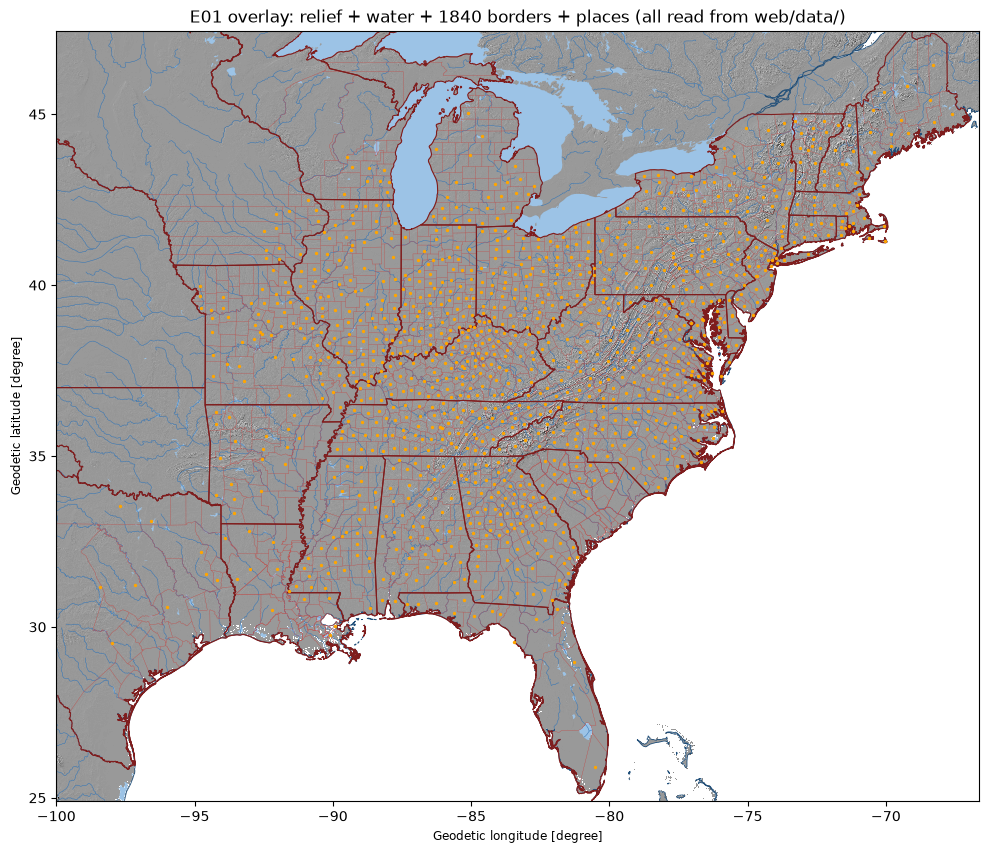

In [9]:
W_, wt = read_topojson(WEB / 'water.topojson')
B_, bt = read_topojson(WEB / 'borders.topojson')
meta = json.loads((WEB / 'relief_bounds.json').read_text())
img = np.array(Image.open(WEB / 'relief.png'))
w, s, e, n = meta['bounds']
pts = q(f"""select lon, lat from places where place_id in (select place_id from residences)
            and lon between {EXTENT[0]} and {EXTENT[2]}""")
fig, ax = plt.subplots(figsize=(14, 10))
ax.imshow(np.ma.masked_where(img[..., 1] == 0, img[..., 0]), cmap='gray', extent=[w, e, s, n], interpolation='nearest')
W_['lakes'].plot(ax=ax, color='#9cc3e6', linewidth=0)
W_['rivers'].plot(ax=ax, color='#3a78b5', linewidth=0.4)
W_['coast'].plot(ax=ax, color='#1f4e79', linewidth=0.6)
c40 = B_['counties'][B_['counties'].years.apply(lambda v: 1840 in v)]
s40 = B_['states'][B_['states'].years.apply(lambda v: 1840 in v)]
c40.boundary.plot(ax=ax, color='#c0504d', linewidth=0.15)
s40.boundary.plot(ax=ax, color='#7f1d1d', linewidth=0.8)
ax.scatter(pts.lon, pts.lat, s=2, color='orange', zorder=5)
ax.set_xlim(EXTENT[0], EXTENT[2]); ax.set_ylim(EXTENT[1], EXTENT[3]); ax.set_aspect(1 / np.cos(np.radians(36)))
ax.set_title('E01 overlay: relief + water + 1840 borders + places (all read from web/data/)')
plt.show()

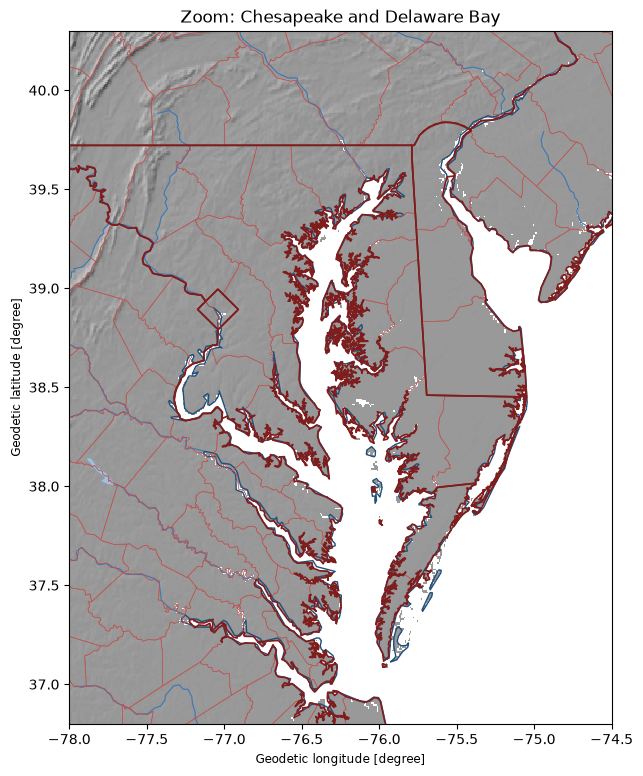

In [10]:
# Zoom: Chesapeake / Delaware Bay, where coast, rivers and county lines should line up closely
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(np.ma.masked_where(img[..., 1] == 0, img[..., 0]), cmap='gray', extent=[w, e, s, n], interpolation='nearest')
W_['rivers'].plot(ax=ax, color='#3a78b5', linewidth=0.8); W_['coast'].plot(ax=ax, color='#1f4e79', linewidth=1)
W_['lakes'].plot(ax=ax, color='#9cc3e6')
c40.boundary.plot(ax=ax, color='#c0504d', linewidth=0.4); s40.boundary.plot(ax=ax, color='#7f1d1d', linewidth=1.2)
ax.set_xlim(-78, -74.5); ax.set_ylim(36.8, 40.3); ax.set_aspect(1 / np.cos(np.radians(38.5)))
ax.set_title('Zoom: Chesapeake and Delaware Bay'); plt.show()

## 6. Assertions

In [11]:
MAX_MB = 10
files = ['relief.png', 'relief_terrarium.png', 'relief_bounds.json', 'water.topojson', 'borders.topojson']
sizes = {f: (WEB / f).stat().st_size / 1e6 for f in files}
display(pd.Series(sizes, name='MB').round(2))
assert all(v < MAX_MB for v in sizes.values()), sizes

# EPSG:4326: decoded coordinates are lon/lat inside the extent; bounds inside the ETOPO subset
tol = 1e-3
for name, t in [('water', wt), ('borders', bt)]:
    x0, y0, x1, y1 = t['bbox']
    assert EXTENT[0] - tol <= x0 and y0 >= EXTENT[1] - tol and x1 <= EXTENT[2] + tol and y1 <= EXTENT[3] + tol, (name, t['bbox'])
assert etopo_box[0] - tol <= w < e <= etopo_box[2] + tol and etopo_box[1] - tol <= s < n <= etopo_box[3] + tol
assert meta['crs'] == 'EPSG:4326'
assert img.shape[:2] == (meta['height'], meta['width'])
for d in list(W_.values()) + list(B_.values()): assert d.crs.to_epsg() == 4326

# rows, unique keys, no null keys, valid geometries
for k, d in W_.items():
    assert len(d) == len(water[k]) > 0, k
    assert d.fid.notna().all() and d.duplicated(['source', 'fid']).sum() == 0, k
    assert not d.featurecla.isin(['Reservoir', 'Canal']).any(), k
for k, d in B_.items():
    assert len(d) == len(borders[k]) > 0, k
    assert d.id.notna().all() and d.id.is_unique, k
    assert d.years.str.len().min() >= 1
    assert d.geom_type.isin(['Polygon', 'MultiPolygon']).all(), k
    for y in SNAPSHOTS: assert d.years.apply(lambda v: y in v).sum() > 0, (k, y)
assert all(not d.geometry.is_empty.any() for d in list(W_.values()) + list(B_.values()))

# Terrarium round trip: decoded elevation matches the downsampled grid to < 1 m
t_img = np.array(Image.open(WEB / 'relief_terrarium.png')).astype('float64')
dec = t_img[..., 0] * 256 + t_img[..., 1] + t_img[..., 2] / 256 - 32768
assert np.abs(dec - zt).max() < 1, np.abs(dec - zt).max()

# every place in the working extent falls inside the relief bounds
assert pts.lon.between(w, e).all() and pts.lat.between(s, n).all()
print('water features:', {k: len(d) for k, d in W_.items()})
print('border versions:', {k: len(d) for k, d in B_.items()})
print('places drawn:', len(pts), '| all checks passed')

relief.png              3.29
relief_terrarium.png    1.48
relief_bounds.json      0.00
water.topojson          0.57
borders.topojson        3.23
Name: MB, dtype: float64

water features: {'rivers': 993, 'lakes': 243, 'coast': 139}
border versions: {'states': 66, 'counties': 2809}
places drawn: 1199 | all checks passed
